In [ ]:
import pandas as pd
import numpy as np
import time, os, re
import nltk
import yfinance as yf
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
     
from tqdm import tqdm
from collections import deque
from dateutil.relativedelta import relativedelta
from datetime import timedelta
from typing import Tuple, Optional, Dict, List, Union
from dataclasses import dataclass

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import minmax_scale
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSequenceClassification   
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [105]:
# پیش‌پردازش متن

FINANCE_KEYWORDS = [

    "inflation","recession","gdp","jobs","unemployment","cpi","ppi",
    "rate","rates","interest","hike","cut","fed","ecb","boe","fomc",
    "stimulus","qe","taper","default","debt","banking","crisis",

    "war","conflict","sanction","election","tariff","trade","china","russia","ukraine",

    "stock","stocks","market","equity","bond","commodity","fx","dollar",
    "bitcoin","crypto","ethereum","gold","oil","brent","wti","opec","energy"
]
KEYWORD_RE = re.compile(r"\b(" + "|".join(FINANCE_KEYWORDS) + r")\b", flags=re.IGNORECASE)

def clean_text(s: str) -> str:
    s = re.sub(r"\s+", " ", str(s)).strip()
    return s

In [106]:
def detect_news_columns(df: pd.DataFrame) -> List[str]:
    cols = []
    for i in range(1, 26):
        for name in (f"Top{i}", f"top{i}", f"TOP{i}"):
            if name in df.columns:
                cols.append(name)
                break
    if cols:
        return cols

    fallback = []
    for c in df.columns:
        cl = c.lower()
        if cl == "date": 
            continue
        if any(tok in cl for tok in ["headline","title","news","text","summary"]):
            fallback.append(c)
    if fallback:
        return fallback

    return [c for c in df.columns if c.lower()!="date" and df[c].dtype=="object"]

In [ ]:
def pick_important_headlines_loose(
    day_row: pd.Series, 
    news_cols: List[str], 
    topk: int = 10,              # سقف تعداد تیتر برای combined_news
    min_keep_if_no_kw: int = 3,  #  حداقل چند تیتر اول برداشته میشه
    fallback_order: str = "top_index"  
) -> str:
    # جمع آوری تیترهای غیرخالی با اطلاعات کمکی
    items = []  # (has_kw, length, top_rank, text)
    for rank, c in enumerate(news_cols, start=1):
        txt = day_row.get(c, "")
        if not isinstance(txt, str):
            continue
        txt = clean_text(txt)
        if not txt:
            continue
        has_kw = 1 if KEYWORD_RE.search(txt) else 0
        items.append((has_kw, len(txt), rank, txt))

    if not items:
        return ""  # هیچ تیتر معتبری در روز نبوده

    # 1) جدا کردن تیترهای کلیدواژه‌دار
    kw_items = [it for it in items if it[0] == 1]
    if kw_items:
        # مرتب‌سازی
        kw_items.sort(key=lambda x: (x[0], x[1]), reverse=True)
        selected = [it[3] for it in kw_items[:topk]]
        if len(selected) < topk:
            # اگر هنوز ظرفیت هست، از بقیه‌ی تیترهای غیرکلیدواژه‌ای طولانی‌تر اضافه میشه
            non_kw = [it for it in items if it[0] == 0]
            non_kw.sort(key=lambda x: x[1], reverse=True)
            need = topk - len(selected)
            selected += [it[3] for it in non_kw[:need]]
        return ", ".join(selected)

    # 2) هیچ تیتر کلیدواژه‌دار نداریم: fallback
    selected = []
    if fallback_order == "top_index":
        # از Top1 به بعد تا حداقل min_keep_if_no_kw
        items_by_rank = sorted(items, key=lambda x: x[2]) 
        selected = [it[3] for it in items_by_rank[:min(min_keep_if_no_kw, len(items_by_rank))]]
       
        if len(selected) < topk:
            remain = [it for it in items_by_rank if it[3] not in selected]
            remain.sort(key=lambda x: x[1], reverse=True)
            need = topk - len(selected)
            selected += [it[3] for it in remain[:need]]
    else:

        items_by_len = sorted(items, key=lambda x: x[1], reverse=True)
        selected = [it[3] for it in items_by_len[:topk]]

    return ", ".join(selected)

In [ ]:
def build_daily_news_loose(news_csv: str, topk: int = 10, min_keep_if_no_kw: int = 3) -> pd.DataFrame:
    df = pd.read_csv(news_csv)

    # یافتن ستون تاریخ
    date_col = next((c for c in df.columns if c.lower()=="date"), None)
    if date_col is None:
        #  بهترین ستون زمانی پیدا بشه
        best, best_valid = None, -1
        for c in df.columns:
            conv = pd.to_datetime(df[c], errors="coerce")
            valid = conv.notna().sum()
            if valid > best_valid:
                best, best_valid = c, valid
        if best is None or best_valid == 0:
            raise ValueError("ستون تاریخ در CSV پیدا نشد.")
        date_col = best

    df["Date"] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)
    df["Date"] = df["Date"].astype("datetime64[ns]")

    news_cols = detect_news_columns(df)
    if not news_cols:
        raise ValueError("ستون‌های خبری یافت نشد.")

    rows = []
    for _, r in df.iterrows():
        cn = pick_important_headlines_loose(
            r, news_cols, topk=topk, min_keep_if_no_kw=min_keep_if_no_kw, fallback_order="top_index"
        )
        if cn:  
            rows.append({"Date": r["Date"], "combined_news": cn})

    out = pd.DataFrame(rows)
    if out.empty:
        raise ValueError("هیچ combined_news ساخته نشد (ورودی‌ها را بررسی کنید).")
    out["Date"] = out["Date"].astype("datetime64[ns]")
    out = out.sort_values("Date").reset_index(drop=True)
    return out

In [109]:
def build_one_table(news_csv: str, tickers: List[str], topk: int = 10, min_keep_if_no_kw: int = 3) -> pd.DataFrame:
    # 1) خبر روزانه با نسخه‌ی شُل‌تر
    news = build_daily_news_loose(news_csv, topk=topk, min_keep_if_no_kw=min_keep_if_no_kw)
    start_dt, end_dt = news["Date"].min().normalize(), news["Date"].max().normalize()

    # 2) قیمت‌ها
    import yfinance as yf
    def download_prices_one(ticker: str, start_dt: pd.Timestamp, end_dt: pd.Timestamp) -> pd.DataFrame:
        start_str = pd.to_datetime(start_dt).strftime("%Y-%m-%d")
        end_plus_one = (pd.to_datetime(end_dt) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        hist = yf.Ticker(ticker).history(start=start_str, end=end_plus_one, interval="1d", auto_adjust=False)
        if hist is None or hist.empty:
            raise RuntimeError(f"داده‌ی قیمت برای '{ticker}' دریافت نشد.")

        idx = pd.to_datetime(hist.index, errors="coerce")
        try:
            if getattr(idx, "tz", None) is not None:
                idx = idx.tz_localize(None)
        except Exception:
            pass
        hist = hist.copy()
        hist.index = idx

        out = hist[["Open","Close"]].copy()
        out["Date"] = out.index
        out["Date"] = pd.to_datetime(out["Date"], errors="coerce").astype("datetime64[ns]")
        out = out.dropna(subset=["Date"]).reset_index(drop=True)

        tag = ticker.replace("=", "_").replace("-", "_")
        out = out.rename(columns={"Open": f"Open_{tag}", "Close": f"Close_{tag}"})
        return out[["Date", f"Open_{tag}", f"Close_{tag}"]].sort_values("Date").reset_index(drop=True)

    price_tables = [download_prices_one(t, start_dt, end_dt) for t in tickers]

    # 3) ادغام همگی بر اساس Date
    merged = news.copy()
    for px in price_tables:
        merged = pd.merge(merged, px, on="Date", how="inner")

    # 4) مرتب‌سازی و ترتیب ستون‌ها
    merged = merged.sort_values("Date").reset_index(drop=True)
    merged["Date"] = merged["Date"].astype("datetime64[ns]")

    price_cols = []
    for t in tickers:
        tag = t.replace("=", "_").replace("-", "_")
        price_cols += [f"Open_{tag}", f"Close_{tag}"]
    merged = merged[["Date", "combined_news"] + price_cols]
    return merged

In [110]:
def download_prices_one(ticker: str, start_dt: pd.Timestamp, end_dt: pd.Timestamp) -> pd.DataFrame:
    import yfinance as yf
    start_str = pd.to_datetime(start_dt).strftime("%Y-%m-%d")
    end_plus_one = (pd.to_datetime(end_dt) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    hist = yf.Ticker(ticker).history(start=start_str, end=end_plus_one, interval="1d", auto_adjust=False)
    if hist is None or hist.empty:
        raise RuntimeError(f"داده‌ی قیمت برای '{ticker}' دریافت نشد.")

    # تاریخ از ایندکس
    idx = pd.to_datetime(hist.index, errors="coerce")
    try:
        # اگر tzدار بود
        if getattr(idx, "tz", None) is not None:
            idx = idx.tz_localize(None)
    except Exception:
        pass
    hist = hist.copy()
    hist.index = idx

    out = hist[["Open","Close"]].copy()
    out["Date"] = out.index
    out["Date"] = pd.to_datetime(out["Date"], errors="coerce").astype("datetime64[ns]")
    out = out.dropna(subset=["Date"]).reset_index(drop=True)

    # برچسب‌گذاری ستون‌ها بر اساس تیکر برای جدول نهایی
    tag = ticker.replace("=", "_").replace("-", "_")
    out = out.rename(columns={
        "Open": f"Open_{tag}",
        "Close": f"Close_{tag}"
    })
    return out[["Date", f"Open_{tag}", f"Close_{tag}"]].sort_values("Date").reset_index(drop=True)


In [ ]:
# ---- ادغام برای یک تیکر ----
def build_stage1_one_ticker(news_csv: str, ticker: str, topk: int = 8) -> pd.DataFrame:
    daily_news = build_daily_news_loose(news_csv, topk=topk)
    start_dt = daily_news["Date"].min().normalize()
    end_dt   = daily_news["Date"].max().normalize()

    prices = download_prices_one(ticker, start_dt, end_dt)

    merged = pd.merge(daily_news, prices, on="Date", how="inner")
    merged = merged.sort_values("Date").reset_index(drop=True)
    merged = merged[["Date", "combined_news", "Open", "Close"]]
    merged["Date"] = merged["Date"].astype("datetime64[ns]")  
    return merged

# ---- پذیرش ورودی لیستی یا رشته‌ای ----
def build_stage1_dataset(
    news_csv: str,
    tickers: Union[str, List[str]],
    topk: int = 8
) -> dict:
    """
    خروجی دیکشنری: {ticker: DataFrame}
    tickers می‌تواند لیست باشد یا رشته با ویرگول
    """
    if isinstance(tickers, str):
        tickers = [t.strip() for t in tickers.split(",") if t.strip()]

    results = {}
    for t in tickers:
        df = build_stage1_one_ticker(news_csv, t, topk=topk)
        results[t] = df
    return results

In [ ]:
NEWS_CSV = r"data\WorldNewsData.csv"
TICKERS  = ["BTC-USD", "GC=F", "CL=F"]

df_all = build_one_table(NEWS_CSV, TICKERS, topk=10, min_keep_if_no_kw=3)

import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
display(df_all.head(20))

,Date,combined_news,Open_BTC_USD,Close_BTC_USD,Open_GC_F,Close_GC_F,Open_CL_F,Close_CL_F
0,2018-05-01,"China’s Social Credit System Punishes Low-Score Parents by Limiting What Schools Their Children Attend, OECD chief s...",9251.469727,9119.009766,1313.199951,1303.800049,68.559998,67.250000
1,2018-05-02,"Half the Australian businesses that got a tax cut have banked the cash, Trump’s shady election data analytics firm j...",9104.599609,9235.919922,1309.000000,1302.599976,67.489998,67.930000
2,2018-05-03,Mexico's presidential frontrunner accuses Mexican billionaires of plotting to prevent him from winning the country's...,9233.969727,9743.860352,1310.699951,1310.699951,67.680000,68.430000
3,2018-05-04,"Donald Trump says London hospital is 'like a war zone for stabbing wounds' as he defends US gun laws, China’s school...",9695.500000,9700.759766,1312.699951,1312.699951,68.500000,69.720001
4,2018-05-07,"China embarks on $72bn tax cuts to counter Trump trade woes, Neilson Barnard/Getty Photographs Lastly, it is the sec...",9645.669922,9373.009766,1310.599976,1312.199951,69.849998,70.730003
5,2018-05-08,Iran Decision: What's at Stake for Global Oil Market? » Gold Silver Reports » Neal Bhai » MCX Tips » Stock Tips » In...,9380.870117,9234.820312,1310.099976,1312.000000,70.029999,69.059998
6,2018-05-09,"Opposition pulls off shock victory at Malaysia general election, Anybody who has performed with Marc-Andre Fleury ca...",9223.730469,9325.179688,1311.300049,1311.300049,70.050003,71.139999
7,2018-05-10,Japan and China agree on security hotline after a decade of talks. The hotline is supposed to defuse any maritime co...,9325.959961,9043.940430,1312.199951,1320.800049,71.230003,71.360001
8,2018-05-14,"Almost half of Australia’s large businesses actively transitioning to cheaper renewable energy, including many going...",8713.099609,8716.790039,1319.900024,1316.500000,70.540001,70.959999
9,2018-05-15,Putin inaugurates controversial bridge by driving a truck across to seized peninsula Crimea. The 12-mile-long bridge...,8705.190430,8510.379883,1304.599976,1288.900024,71.150002,71.309998


مرحله دوم

In [113]:
def ensure_datetime64_ns(df: pd.DataFrame, date_col: str = "Date") -> pd.DataFrame:
    if date_col not in df.columns:
        raise ValueError(f"ستون '{date_col}' وجود ندارد.")
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col], errors="coerce").astype("datetime64[ns]")
    out = out.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)
    return out

In [ ]:
def _split_train_val(trainval_df: pd.DataFrame, date_col: str, val_frac: float = 0.2,
                     min_train_rows: int = 50, min_val_rows: int = 20):
    # جداکردن Validation از انتهای Train
    if len(trainval_df) < (min_train_rows + min_val_rows):
        # اگر کم بود، همون 80/20 روی کل trainval
        split_idx = max(int(len(trainval_df) * (1 - val_frac)), 1)
        train_df = trainval_df.iloc[:split_idx].copy()
        val_df   = trainval_df.iloc[split_idx:].copy()
    else:
        val_len = max(int(len(trainval_df) * val_frac), min_val_rows)
        val_len = min(val_len, len(trainval_df) - min_train_rows)
        if val_len <= 0:
            val_len = max(1, int(len(trainval_df) * 0.1))
        split_idx = len(trainval_df) - val_len
        train_df = trainval_df.iloc[:split_idx].copy()
        val_df   = trainval_df.iloc[split_idx:].copy()

    train_df = train_df.sort_values(date_col).reset_index(drop=True)
    val_df   = val_df.sort_values(date_col).reset_index(drop=True)
    return train_df, val_df

In [115]:
def calendar_9m_split(df: pd.DataFrame, date_col: str = "Date",
                      val_frac_of_train: float = 0.2,
                      align_test_start: str = "exact"):
    df = ensure_datetime64_ns(df, date_col)

    max_dt = df[date_col].max()
    raw_cut = max_dt - relativedelta(months=9)

    # هم‌ترازی مرز تست
    if align_test_start == "exact":
        test_start = raw_cut
    elif align_test_start == "month_start":
        test_start = (raw_cut + relativedelta(day=1, months=+1)).normalize()
    elif align_test_start == "month_end":
        month_end = (raw_cut + relativedelta(day=31))  # day=31 => آخر ماه
        test_start = (month_end + pd.Timedelta(days=1)).normalize()
    else:
        raise ValueError("align_test_start باید یکی از {'exact','month_start','month_end'} باشد.")

    # جداسازی
    test_df     = df[df[date_col] >= test_start].copy()
    trainval_df = df[df[date_col] <  test_start].copy()

    # اگر تست خیلی کوچک بود، همون برگردانده میشه
    train_df, val_df = _split_train_val(trainval_df, date_col, val_frac_of_train)
    return train_df, val_df, test_df.sort_values(date_col).reset_index(drop=True), test_start

In [ ]:
def percent_last_split(df: pd.DataFrame, date_col: str = "Date",
                       test_frac: float = 0.2, val_frac_of_train: float = 0.2):
    df = ensure_datetime64_ns(df, date_col)
    n = len(df)
    cutoff_idx = max(int(n * (1 - test_frac)), 1)
    trainval_df = df.iloc[:cutoff_idx].copy()
    test_df     = df.iloc[cutoff_idx:].copy()
    train_df, val_df = _split_train_val(trainval_df, date_col, val_frac_of_train)
    return train_df, val_df, test_df.sort_values(date_col).reset_index(drop=True)

In [117]:
def time_based_split(
    df: pd.DataFrame,
    date_col: str = "Date",
    test_last_months: int = 9,
    val_frac_of_train: float = 0.2,
    min_train_rows: int = 50,
    min_val_rows: int = 20,
    min_test_rows: int = 20,
):
    df = ensure_datetime64_ns(df, date_col=date_col)
    if df.empty:
        raise ValueError("دیتافریم خالی است.")

    max_dt = df[date_col].max()
    test_start_dt = max_dt - relativedelta(months=test_last_months)

    # جداسازی تست (۹ ماه آخر)
    test_df = df[df[date_col] >= test_start_dt].copy()
    trainval_df = df[df[date_col] <  test_start_dt].copy()

    # کنترل کفِ تعداد ردیف‌ها
    if len(test_df) < min_test_rows:
        # اگر دیتاست کوچک است، حداقل 20% آخر را به عنوان تست بردار
        cutoff_idx = int(len(df) * 0.8)
        trainval_df = df.iloc[:cutoff_idx].copy()
        test_df     = df.iloc[cutoff_idx:].copy()

    # اگر باز هم کوچک بود
    if len(trainval_df) < (min_train_rows + min_val_rows):
        # تقسیم 80/20 روی کل دیتای غیرتست (یا کل دیتاست اگر حالت fallback بود)
        cutoff_idx = max(int(len(trainval_df) * (1 - val_frac_of_train)), 1)
        train_df = trainval_df.iloc[:cutoff_idx].copy()
        val_df   = trainval_df.iloc[cutoff_idx:].copy()
        return (
            train_df.sort_values(date_col).reset_index(drop=True),
            val_df.sort_values(date_col).reset_index(drop=True),
            test_df.sort_values(date_col).reset_index(drop=True),
        )

    # جدا کردن ولیدیشن از انتهای بازه‌ی Train
    val_len = max(int(len(trainval_df) * val_frac_of_train), min_val_rows)
    val_len = min(val_len, len(trainval_df) - min_train_rows)  
    if val_len <= 0:
        val_len = max(1, int(len(trainval_df) * 0.1))
    split_idx = len(trainval_df) - val_len

    train_df = trainval_df.iloc[:split_idx].copy()
    val_df   = trainval_df.iloc[split_idx:].copy()

    # مرتب‌سازی نهایی (زمان‌محور)
    train_df = train_df.sort_values(date_col).reset_index(drop=True)
    val_df   = val_df.sort_values(date_col).reset_index(drop=True)
    test_df  = test_df.sort_values(date_col).reset_index(drop=True)

    return train_df, val_df, test_df

In [118]:
# --- حالت 1: تقویمی ۹ ماه ---
train_cal, val_cal, test_cal, test_start = calendar_9m_split(
    df_all,
    date_col="Date",
    val_frac_of_train=0.2,
    align_test_start="month_end"  
)
print("Calendar-9M  | test_start =", test_start.date(),
      "| Train:", (train_cal["Date"].min(), train_cal["Date"].max(), len(train_cal)),
      "| Val:",   (val_cal["Date"].min(), val_cal["Date"].max(), len(val_cal)),
      "| Test:",  (test_cal["Date"].min(), test_cal["Date"].max(), len(test_cal)))

# --- حالت 2: درصدی ۲۰٪ آخر ---
train_pct, val_pct, test_pct = percent_last_split(
    df_all,
    date_col="Date",
    test_frac=0.20,
    val_frac_of_train=0.20
)
print("Percent-20%  | Train:", (train_pct["Date"].min(), train_pct["Date"].max(), len(train_pct)),
      "| Val:",     (val_pct["Date"].min(), val_pct["Date"].max(), len(val_pct)),
      "| Test:",    (test_pct["Date"].min(), test_pct["Date"].max(), len(test_pct)))

# نمایش چند سطر اول برای اطمینان
from IPython.display import display
pd.set_option("display.max_colwidth", 120)
display(test_cal.head(3))
display(test_pct.head(3))

Calendar-9M  | test_start = 2021-09-01 | Train: (Timestamp('2018-05-01 00:00:00'), Timestamp('2020-05-29 00:00:00'), 63) | Val: (Timestamp('2021-05-03 00:00:00'), Timestamp('2021-05-28 00:00:00'), 20) | Test: (Timestamp('2022-05-02 00:00:00'), Timestamp('2022-05-31 00:00:00'), 21)
Percent-20%  | Train: (Timestamp('2018-05-01 00:00:00'), Timestamp('2020-05-29 00:00:00'), 63) | Val: (Timestamp('2021-05-03 00:00:00'), Timestamp('2021-05-28 00:00:00'), 20) | Test: (Timestamp('2022-05-02 00:00:00'), Timestamp('2022-05-31 00:00:00'), 21)


,Date,combined_news,Open_BTC_USD,Close_BTC_USD,Open_GC_F,Close_GC_F,Open_CL_F,Close_CL_F
0,2022-05-02,"Putin is inching towards his nukes, threatening to annihilate the world if he fails to capture Ukraine, says foreign...",38472.187500,38529.328125,1896.699951,1861.800049,104.000000,105.169998
1,2022-05-03,"The Pope says the Russians are learning that 'their tanks are useless' in Ukraine, Slovakia, Hungary will not suppor...",38528.109375,37750.453125,1868.800049,1868.800049,105.080002,102.410004
2,2022-05-04,Russia's demolition of the Mariupol theater and the alleged removal of bodies could be a sign they're trying to 'hid...,37748.011719,39698.371094,1867.000000,1867.000000,103.500000,107.809998


,Date,combined_news,Open_BTC_USD,Close_BTC_USD,Open_GC_F,Close_GC_F,Open_CL_F,Close_CL_F
0,2022-05-02,"Putin is inching towards his nukes, threatening to annihilate the world if he fails to capture Ukraine, says foreign...",38472.187500,38529.328125,1896.699951,1861.800049,104.000000,105.169998
1,2022-05-03,"The Pope says the Russians are learning that 'their tanks are useless' in Ukraine, Slovakia, Hungary will not suppor...",38528.109375,37750.453125,1868.800049,1868.800049,105.080002,102.410004
2,2022-05-04,Russia's demolition of the Mariupol theater and the alleged removal of bodies could be a sign they're trying to 'hid...,37748.011719,39698.371094,1867.000000,1867.000000,103.500000,107.809998


مرحله سوم و چهارم

In [119]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LOOKBACK = 14           
BATCH    = 64
EPOCHS   = 60
LR       = 1e-3
WEIGHT_DECAY = 1e-4   # Regularization در Adam

In [120]:
# ---------- ابزارهای عمومی ----------
def ticker_tag(t):
    return t.replace("=", "_").replace("-", "_")
def open_close_cols(t): 
    tag = ticker_tag(t)
    return f"Open_{tag}", f"Close_{tag}"

def ensure_datetime64_ns(df, date_col="Date"):
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col], errors="coerce").astype("datetime64[ns]")
    out = out.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)
    return out

In [121]:
# ---------- ساخت ویژگی‌های عددی روزانه از df_all ----------
# (برای هر دارایی موجود در جدول)
def build_numeric_panel(df_all: pd.DataFrame, tickers: list) -> pd.DataFrame:
    df = ensure_datetime64_ns(df_all, "Date").copy()
    feat_cols = []
    for t in tickers:
        oc, cc = open_close_cols(t)
        if oc not in df.columns or cc not in df.columns:
            raise ValueError(f"{t}: ستون‌های {oc}/{cc} در df_all نیستند.")
        df[f"ret_intraday_{ticker_tag(t)}"] = (df[cc] / df[oc] - 1.0)
        df[f"ret_day_{ticker_tag(t)}"]      = df[cc].pct_change(1)
        feat_cols += [oc, cc, f"ret_intraday_{ticker_tag(t)}", f"ret_day_{ticker_tag(t)}"]
    df[feat_cols] = df[feat_cols].astype(float).fillna(0.0)   
    return df[["Date"] + feat_cols]

In [ ]:
# ---------- امبدینگ  ----------
def compute_news_embeddings(texts: pd.Series, model_name="sentence-transformers/all-MiniLM-L6-v2"):
    st = SentenceTransformer(model_name)
    embs = st.encode(texts.fillna("").tolist(), show_progress_bar=True, normalize_embeddings=True)
    return np.asarray(embs, dtype=np.float32)  

# ---------- احساسات ----------
def compute_finbert_sentiment(texts: pd.Series, batch_size=16)-> np.ndarray:
    try:
        device = "cuda" if torch.cuda.is_available() else "cpu"
        name = "ProsusAI/finbert"
        tok = AutoTokenizer.from_pretrained(name)
        mdl = AutoModelForSequenceClassification.from_pretrained(name).to(device)
        id2label = mdl.config.id2label
        label2idx = {v.lower(): k for k,v in id2label.items()}
        pos_i, neg_i, neu_i = label2idx["positive"], label2idx["negative"], label2idx["neutral"]

        probs_all = []
        lst = texts.fillna("").tolist()
        for i in tqdm(range(0, len(lst), batch_size), desc="FinBERT sentiment"):
            batch = lst[i:i+batch_size]
            enc = tok(batch, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
            with torch.no_grad():
                logits = mdl(**enc).logits
                probs = F.softmax(logits, dim=-1).cpu().numpy()
            probs_all.append(probs)
        probs_all = np.vstack(probs_all)
        pos, neg, neu = probs_all[:,pos_i], probs_all[:,neg_i], probs_all[:,neu_i]
        compound = pos - neg
        feats = np.stack([pos, neg, neu, compound], axis=1).astype(np.float32)
        return feats
    except Exception:
        sia = SentimentIntensityAnalyzer()
        pos, neg, neu, comp = [], [], [], []
        for t in tqdm(texts.fillna("").tolist(), desc="VADER sentiment"):
            s = sia.polarity_scores(t)
            pos.append(s["pos"]); neg.append(s["neg"]); neu.append(s["neu"]); comp.append(s["compound"])
        feats = np.stack([pos, neg, neu, comp], axis=1).astype(np.float32)
        return feats

In [123]:
# ---------- ساخت توالی‌ها با جداسازی عددی/متنی ----------
def make_sequences_for_variant(
    df_all: pd.DataFrame,
    target_ticker: str,
    tickers_for_numeric: list,
    variant: str = "num",
    lookback: int = LOOKBACK
):
    df_num = build_numeric_panel(df_all, tickers_for_numeric)
    num_daily = df_num.drop(columns=["Date"]).values.astype("float32")  

    # extra per-day
    extra_daily = None
    if "combined_news" not in df_all.columns:
        raise ValueError("combined_news در df_all موجود نیست.")
    txt = df_all.loc[df_num.index, "combined_news"]
    if variant == "num_emb":
        extra_daily = compute_news_embeddings(txt)  #  (L2-normalized already)
    elif variant == "num_sent":
        extra_daily = compute_finbert_sentiment(txt)  

    # y = Close_{t+1} هدف
    _, close_col = open_close_cols(target_ticker)
    y_all = df_all.loc[df_num.index, close_col].astype(float).shift(-1).values.astype("float32")

    Xn, Xe, y, dates = [], [], [], []
    for i in range(lookback, len(df_num) - 1):
        Xn.append(num_daily[i-lookback:i, :])
        if extra_daily is not None:
            Xe.append(extra_daily[i-lookback:i, :])
        y.append(y_all[i])  
        dates.append(df_num["Date"].iloc[i])
    Xn = np.stack(Xn) if len(Xn) else np.zeros((0, lookback, num_daily.shape[1]), dtype="float32")
    Xe = (np.stack(Xe) if len(Xe) else None) if extra_daily is not None else None
    y  = np.array(y, dtype="float32")
    dates = pd.Series(dates)
    return Xn, Xe, y, dates

In [124]:
# ---------- نگاشت تاریخ به ایندکس برای split مرحله ۲ ----------
def idx_from_dates(master_dates: pd.Series, sub_df: pd.DataFrame):
    mask = master_dates.isin(pd.to_datetime(sub_df["Date"]).astype("datetime64[ns]"))
    return np.where(mask.values)[0]

In [125]:
# ---------- مدل GRU با Regularization ----------
class GRUReg(nn.Module):
    def __init__(self, n_features, hidden=64, layers=2, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(input_size=n_features, hidden_size=hidden, num_layers=layers,
                          batch_first=True, dropout=dropout if layers>1 else 0.0)
        self.norm = nn.LayerNorm(hidden)                #  LayerNorm
        self.head = nn.Sequential(
            nn.Dropout(dropout),                        #  Dropout در Head
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        out, _ = self.gru(x)
        last = out[:, -1, :]
        last = self.norm(last)
        return self.head(last).squeeze(-1)

def train_gru(Xtr, ytr, Xva, yva, n_features):
    model = GRUReg(n_features).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY) 
    loss_fn = nn.MSELoss()

    def loader(X, y, shuffle):
        ds = torch.utils.data.TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))
        return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle)
    tr_loader, va_loader = loader(Xtr, ytr, True), loader(Xva, yva, False)

    best_state, best_val = None, np.inf
    for ep in range(1, EPOCHS+1):
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); pred = model(xb); loss = loss_fn(pred, yb); loss.backward(); opt.step()
        # validation
        model.eval(); losses=[]
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                losses.append(loss_fn(model(xb), yb).item())
        v = float(np.mean(losses)) if losses else np.inf
        if v < best_val:
            best_val = v
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    return model

In [126]:
# ---------- معیارها ----------
def rmse(y_true, y_pred): 
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def directional_accuracy(y_true, y_pred, close_today):
    a = np.sign(y_true - close_today)
    p = np.sign(y_pred - close_today)
    return float((a == p).mean())

In [127]:
# ---------- آموزش/ارزیابی یک واریانت با Scaling مجزا ----------
def train_eval_variant(df_all, train_df, val_df, test_df, target_ticker, tickers_for_numeric, variant):
    # 1) ساخت توالی‌ها
    Xn_all, Xe_all, y_all, dates_all = make_sequences_for_variant(
        df_all, target_ticker, tickers_for_numeric, variant, LOOKBACK
    )
    if len(Xn_all) == 0:
        raise ValueError("طول توالی‌ها صفر شد.")

    # 2) ایندکس‌ها
    idx_tr = idx_from_dates(dates_all, train_df)
    idx_va = idx_from_dates(dates_all, val_df)
    idx_te = idx_from_dates(dates_all, test_df)

    # 3) اسکیلینگِ جداگانه: عددی و (در صورت وجود) احساسات
    #   * Embedding ها L2-normalized هستند ⇒ بدون اسکیلر؛ فقط concat می‌شوند
    scaler_num = StandardScaler().fit(Xn_all[np.r_[idx_tr, idx_va]].reshape(len(np.r_[idx_tr, idx_va]), -1))
    def scale_block(X, scaler):
        N,T,F = X.shape
        return scaler.transform(X.reshape(N, -1)).reshape(N, T, F).astype("float32")
    Xn_tr, Xn_va, Xn_te = scale_block(Xn_all[idx_tr], scaler_num), scale_block(Xn_all[idx_va], scaler_num), scale_block(Xn_all[idx_te], scaler_num)

    Xe_tr = Xe_va = Xe_te = None
    scaler_sent = None
    if variant == "num_sent" and Xe_all is not None:
        scaler_sent = StandardScaler().fit(Xe_all[np.r_[idx_tr, idx_va]].reshape(len(np.r_[idx_tr, idx_va]), -1))
        Xe_tr = scale_block(Xe_all[idx_tr], scaler_sent)
        Xe_va = scale_block(Xe_all[idx_va], scaler_sent)
        Xe_te = scale_block(Xe_all[idx_te], scaler_sent)
    elif variant == "num_emb" and Xe_all is not None:
        Xe_tr, Xe_va, Xe_te = Xe_all[idx_tr], Xe_all[idx_va], Xe_all[idx_te]

    # 4) concat در محور ویژگی‌ها
    def cat(num, extra):
        return np.concatenate([num, extra], axis=-1) if extra is not None else num
    Xtr = cat(Xn_tr, Xe_tr);  Xva = cat(Xn_va, Xe_va);  Xte = cat(Xn_te, Xe_te)

    # 5) اسکیلینگِ y فقط بر اساس Train
    scaler_y = StandardScaler().fit(y_all[idx_tr].reshape(-1,1))
    ytr = scaler_y.transform(y_all[idx_tr].reshape(-1,1)).ravel().astype("float32")
    yva = scaler_y.transform(y_all[idx_va].reshape(-1,1)).ravel().astype("float32")
    yte_true = y_all[idx_te].astype("float32")

    # 6) آموزش
    model = train_gru(Xtr, ytr, Xva, yva, n_features=Xtr.shape[-1])

    # 7) پیش‌بینی روی Test و بازگردانی مقیاس
    model.eval()
    with torch.no_grad():
        yhat_std = model(torch.tensor(Xte, dtype=torch.float32).to(DEVICE)).cpu().numpy()
    yhat = scaler_y.inverse_transform(yhat_std.reshape(-1,1)).ravel()

    # 8) معیارها
    def rmse(a,b): return float(np.sqrt(np.mean((a-b)**2)))
    def directional_accuracy(y_true, y_pred, close_today):
        a = np.sign(y_true - close_today); p = np.sign(y_pred - close_today)
        return float((a==p).mean())

    _, cc = open_close_cols(target_ticker)
    close_today = df_all[cc].astype(float)
    close_today = close_today.loc[df_all["Date"].isin(dates_all.iloc[idx_te])].values.astype("float32")

    return {
        "dates_test": dates_all.iloc[idx_te].reset_index(drop=True),
        "y_true": yte_true,
        "y_pred": yhat,
        "rmse": rmse(yte_true, yhat),
        "da": directional_accuracy(yte_true, yhat, close_today)
    }

In [128]:
# ---------- رسم ----------
def plot_models_timeseries(dates, y_true, yhat_dict, title, log_scale=False):
    plt.figure(figsize=(11,5))
    plt.plot(dates, y_true, label="Actual", linewidth=2)
    for k,v in yhat_dict.items():
        plt.plot(dates, v, linestyle="--", marker="o", label=k)
    if log_scale: plt.yscale("log")
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Next-day Close")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_metrics_bar(res_dict, split_name=""):
    models = list(res_dict.keys())
    rmses  = [res_dict[m]["rmse"] for m in models]
    das    = [res_dict[m]["da"]*100 for m in models]
    fig,ax = plt.subplots(1,2,figsize=(12,4))
    ax[0].bar(models, rmses)
    ax[0].set_title(f"RMSE — {split_name}")
    ax[0].set_ylabel("RMSE")
    ax[0].grid(axis="y", ls=":", alpha=.4)
    ax[1].bar(models, das)
    ax[1].set_title(f"Directional Accuracy — {split_name}")
    ax[1].set_ylabel("%")
    ax[1].grid(axis="y", ls=":", alpha=.4)
    plt.tight_layout()
    plt.show()

VADER sentiment: 100%|██████████| 104/104 [00:00<00:00, 218.03it/s]


Numeric      | RMSE=17777.0781 | DA=55.00%
Numeric+Emb  | RMSE=12234.8340 | DA=55.00%
Numeric+Sent | RMSE=20664.2109 | DA=55.00%


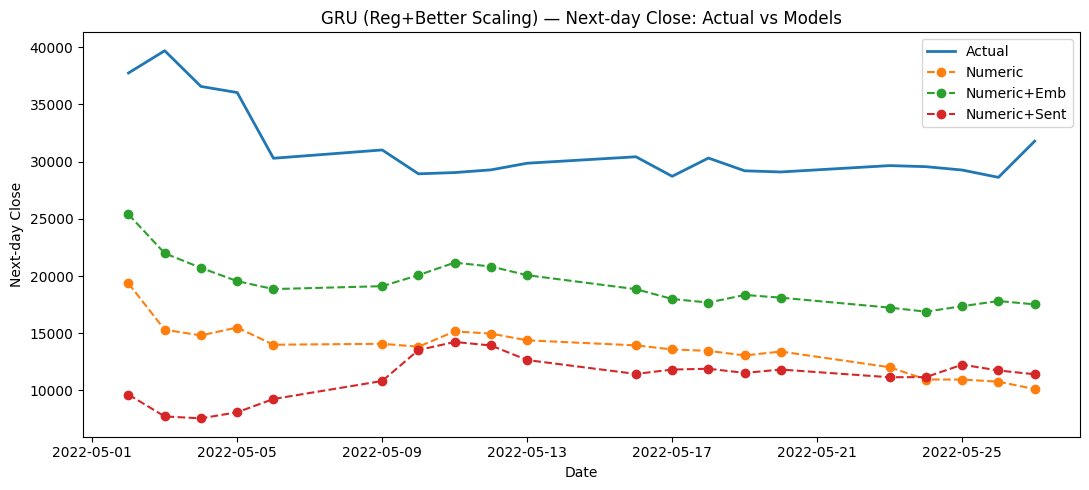

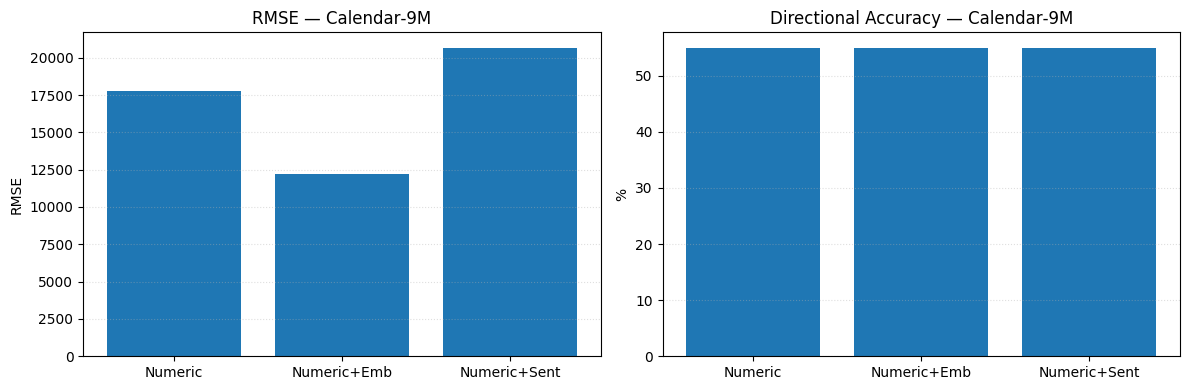

In [ ]:
TARGET_TICKER     = "BTC-USD"
NUMERIC_TICKERS   = ["BTC-USD", "GC=F", "CL=F"]

res_num      = train_eval_variant(df_all, train_cal, val_cal, test_cal, TARGET_TICKER, NUMERIC_TICKERS, variant="num")
res_num_emb  = train_eval_variant(df_all, train_cal, val_cal, test_cal, TARGET_TICKER, NUMERIC_TICKERS, variant="num_emb")
res_num_sent = train_eval_variant(df_all, train_cal, val_cal, test_cal, TARGET_TICKER, NUMERIC_TICKERS, variant="num_sent")

print(f"Numeric      | RMSE={res_num['rmse']:.4f} | DA={100*res_num['da']:.2f}%")
print(f"Numeric+Emb  | RMSE={res_num_emb['rmse']:.4f} | DA={100*res_num_emb['da']:.2f}%")
print(f"Numeric+Sent | RMSE={res_num_sent['rmse']:.4f} | DA={100*res_num_sent['da']:.2f}%")

plot_models_timeseries(
    dates=res_num["dates_test"],
    y_true=res_num["y_true"],
    yhat_dict={"Numeric":res_num["y_pred"], "Numeric+Emb":res_num_emb["y_pred"], "Numeric+Sent":res_num_sent["y_pred"]},
    title="GRU (Reg+Better Scaling) — Next-day Close: Actual vs Models",
    log_scale=False
)

plot_metrics_bar({"Numeric":res_num, "Numeric+Emb":res_num_emb, "Numeric+Sent":res_num_sent}, split_name="Calendar-9M")

مرحله پنجم

In [131]:
# ------------------ Config ------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LOOKBACK = 20          # طول پنجره‌ی ورودی LSTM برراساس روز
EPOCHS = 80
LR = 1e-3
BATCH = 64
HORIZONS = [3, 5, 10]
TICKERS = ["BTC-USD", "GC=F", "CL=F"]  

def ticker_tag(t): return t.replace("=", "_").replace("-", "_")
def open_close_cols(t): 
    tag = ticker_tag(t); 
    return f"Open_{tag}", f"Close_{tag}"

def ensure_datetime64_ns(df, date_col="Date"):
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col], errors="coerce").astype("datetime64[ns]")
    out = out.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)
    return out

In [132]:
# ------------------ Feature Engineering (numeric) ------------------
def build_feature_table(df_all: pd.DataFrame) -> pd.DataFrame:
    df = ensure_datetime64_ns(df_all, "Date").copy()
    feat_cols = []
    for t in TICKERS:
        op, cl = open_close_cols(t)
        assert op in df.columns and cl in df.columns, f"ستون‌های {t} یافت نشد."
        df[f"ret_intraday_{ticker_tag(t)}"] = (df[cl] / df[op] - 1.0).astype(float)
        df[f"ret_day_{ticker_tag(t)}"]      = df[cl].pct_change(1).astype(float)
        feat_cols += [op, cl, f"ret_intraday_{ticker_tag(t)}", f"ret_day_{ticker_tag(t)}"]
    df[feat_cols] = df[feat_cols].fillna(0.0)
    return df[["Date"] + feat_cols]

def make_sequences(df_feats: pd.DataFrame, target_ticker: str, lookback=LOOKBACK):
    t_op, t_cl = open_close_cols(target_ticker)
    feat_cols = [c for c in df_feats.columns if c != "Date"]
    data = df_feats[feat_cols].values.astype("float32")
    close_target = df_feats[t_cl].values.astype("float32")

    X_raw = []
    y_raw = []
    dates = []

    for i in range(lookback, len(df_feats)-1):  # -1 چون y = Close_{i+1}
        X_raw.append(data[i-lookback:i, :])
        y_raw.append(close_target[i+1])
        dates.append(df_feats["Date"].iloc[i])   # تاریخ «پایان پنجره» (روز t)

    X_raw = np.stack(X_raw)          
    y_raw = np.array(y_raw)          
    dates = pd.Series(dates)
    return X_raw, y_raw, dates, feat_cols

In [133]:
# ------------------ Train/Val/Test indexing by dates ------------------
def idx_from_dates(master_dates: pd.Series, sub_df: pd.DataFrame):
    mask = master_dates.isin(pd.to_datetime(sub_df["Date"]).astype("datetime64[ns]"))
    return np.where(mask.values)[0]

In [134]:
# ------------------ LSTM Model ------------------
class PriceLSTM(nn.Module):
    def __init__(self, n_features, hidden=64, n_layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden, num_layers=n_layers,
                            batch_first=True, dropout=dropout if n_layers>1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):  # x: [B, T, F]
        out, _ = self.lstm(x)
        last = out[:, -1, :]          #  آخرین time-step
        pred = self.head(last)        
        return pred.squeeze(-1)       

def train_lstm(X_tr, y_tr, X_va, y_va, n_features):
    torch.manual_seed(42)
    model = PriceLSTM(n_features=n_features).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()

    # DataLoaders
    def to_loader(X, y, shuffle):
        ds = torch.utils.data.TensorDataset(torch.tensor(X, dtype=torch.float32),
                                            torch.tensor(y, dtype=torch.float32))
        return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=False)
    tr_loader = to_loader(X_tr, y_tr, True)
    va_loader = to_loader(X_va, y_va, False)

    best_state, best_va = None, np.inf
    for ep in range(1, EPOCHS+1):
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); pred = model(xb); loss = loss_fn(pred, yb); loss.backward(); opt.step()
        # validation
        model.eval(); va_losses=[]
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb); va_losses.append(loss_fn(pred, yb).item())
        va_mse = float(np.mean(va_losses)) if va_losses else np.inf
        if va_mse < best_va:
            best_va = va_mse
            best_state = {k:v.cpu().clone() for k,v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    return model

In [ ]:
# ------------------ Fit per-asset LSTM using Train+Val ------------------
def fit_lstm_for_asset(df_all, train_df, val_df, target_ticker):
    # 1) جدول ویژگی‌ها
    df_feats = build_feature_table(df_all)
    # 2) توالی‌ها
    X_raw, y_raw, dates, feat_cols = make_sequences(df_feats, target_ticker, LOOKBACK)
    # 3) ایندکس‌های Train/Val
    idx_tr = idx_from_dates(dates, train_df)
    idx_va = idx_from_dates(dates, val_df)

    # 4) اسکیلینگ فقط بر اساس Train+Val
    scaler_x = StandardScaler().fit(X_raw[idx_tr].reshape(len(idx_tr), -1))
    scaler_y = StandardScaler().fit(y_raw[idx_tr].reshape(-1,1))

    def transform_blocks(X, scaler):
        N,T,F = X.shape
        X2 = scaler.transform(X.reshape(N,-1)).reshape(N,T,F)
        return X2

    X_tr = transform_blocks(X_raw[idx_tr], scaler_x)
    X_va = transform_blocks(X_raw[idx_va], scaler_x)
    y_tr = scaler_y.transform(y_raw[idx_tr].reshape(-1,1)).ravel()
    y_va = scaler_y.transform(y_raw[idx_va].reshape(-1,1)).ravel()

    # 5) آموزش
    model = train_lstm(X_tr, y_tr, X_va, y_va, n_features=X_tr.shape[-1])

    meta = {
        "feat_cols": feat_cols,
        "scaler_x": scaler_x,
        "scaler_y": scaler_y,
        "dates": dates,               # تاریخِ «پایان پنجره» برای X_raw[i]
        "X_raw": X_raw,             
        "df_feats": df_feats          #  بازیابی آخرین فیچرهای واقعی
    }
    return model, meta

In [135]:
# ------------------ Recursive Forecast (per-asset) ------------------
def recursive_forecast_lstm(df_all, model, meta, target_ticker, horizon):
    df_feats = meta["df_feats"].copy()
    feat_cols = meta["feat_cols"]
    scaler_x, scaler_y = meta["scaler_x"], meta["scaler_y"]

    # آخرین پنجره‌ی واقعی
    last_block = df_feats.iloc[-LOOKBACK:].copy()

    # ستون‌های کلوز هر دارایی را پیدا کرده
    close_cols = {t: open_close_cols(t)[1] for t in TICKERS}
    open_cols  = {t: open_close_cols(t)[0] for t in TICKERS}
    target_close_col = close_cols[target_ticker]

    preds = []
    cur_date = df_feats["Date"].iloc[-1]

    for step in range(1, horizon+1):
        # 1) ساخت X_t (ویژگی‌های روز t) از آخرین LOOKBACK ردیف
        X_block = last_block.drop(columns=["Date"]).values.astype("float32")[None, :, :] 
        X_block_std = scaler_x.transform(X_block.reshape(1, -1)).reshape(1, LOOKBACK, -1)
        # 2) پیش‌بینی Close_{t+1}
        model.eval()
        with torch.no_grad():
            y_hat_std = model(torch.tensor(X_block_std, dtype=torch.float32, device=DEVICE)).cpu().numpy()[0]
        y_hat = scaler_y.inverse_transform([[y_hat_std]])[0,0]

        # 3) ردیف «مصنوعیِ t+1» را بسازیم (persistence برای سایر فیچرها)
        next_row = last_block.iloc[-1].copy()
        next_row["Date"] = pd.to_datetime(cur_date) + pd.Timedelta(days=1)

        # برای همه‌ی دارایی‌ها: Open_{t+1} = Close_t
        for t in TICKERS:
            oc, cc = open_close_cols(t)
            next_row[oc] = last_block.iloc[-1][cc]

        # close هدف = y_hat
        next_row[target_close_col] = y_hat

        # برای سایر دارایی‌ها close را persistence می‌گیریم
        for t in TICKERS:
            cc = close_cols[t]
            if cc != target_close_col:
                next_row[cc] = last_block.iloc[-1][cc]

        # محاسبه دوباره بازده‌ها
        for t in TICKERS:
            tag = ticker_tag(t)
            oc, cc = open_close_cols(t)
            next_row[f"ret_intraday_{tag}"] = (next_row[cc] / next_row[oc] - 1.0) if next_row[oc] else 0.0
            prev_close = last_block.iloc[-1][cc]
            next_row[f"ret_day_{tag}"]      = (next_row[cc] / prev_close - 1.0) if prev_close else 0.0

        last_block = pd.concat([last_block, pd.DataFrame([next_row])], ignore_index=True).iloc[-LOOKBACK:]

        preds.append({"Date": next_row["Date"], f"Close_pred_{ticker_tag(target_ticker)}": y_hat})
        cur_date = next_row["Date"]

    out = pd.DataFrame(preds)
    out["Date"] = pd.to_datetime(out["Date"]).astype("datetime64[ns]")
    return out

In [136]:
# ------------------ High-level: fit & forecast for all assets ------------------
def train_and_recursive_forecast_all(df_all, train_df, val_df, horizons=HORIZONS):
    models = {}
    metas  = {}
    forecasts = {t:{} for t in TICKERS}

    for t in TICKERS:
        mdl, meta = fit_lstm_for_asset(df_all, train_df, val_df, t)
        models[t] = mdl; metas[t] = meta
        for h in horizons:
            forecasts[t][h] = recursive_forecast_lstm(df_all, mdl, meta, t, h)
    return models, metas, forecasts

In [137]:
# ------------------ Plotting (log-scale + multi-horizon) ------------------
def get_actual_close(df_all, ticker):
    df = ensure_datetime64_ns(df_all, "Date")
    _, cc = open_close_cols(ticker)
    return df[["Date", cc]].rename(columns={cc: "Close_actual"})

def plot_asset_with_horizons(df_all, forecasts_for_one_asset: dict, ticker: str, lookback_days=120, save=None):
    hist = get_actual_close(df_all, ticker)
    max_dt = hist["Date"].max()
    min_dt = max_dt - pd.Timedelta(days=lookback_days)
    hist_win = hist[hist["Date"] >= min_dt].copy()

    tag = ticker_tag(ticker)
    plt.figure(figsize=(11,5))
    plt.plot(hist_win["Date"], hist_win["Close_actual"], label=f"{ticker} Actual")
    for h, fc in forecasts_for_one_asset.items():
        plt.plot(fc["Date"], fc[f"Close_pred_{tag}"], marker="o", linestyle="--", label=f"Forecast {h}d")
    plt.yscale("log")  
    plt.title(f"Recursive LSTM Forecasts — {ticker}")
    plt.xlabel("Date"); plt.ylabel("Close (log)")
    plt.legend(); plt.tight_layout()
    if save: 
        plt.savefig(save, dpi=150)
        print("Saved:", save)
    plt.show()

def plot_compare_assets(df_all, forecasts_dict: dict, horizon: int, lookback_days=120, normalize=True, save=None):
    plt.figure(figsize=(12,6))
    for t, hmap in forecasts_dict.items():
        hist = get_actual_close(df_all, t)
        max_dt = hist["Date"].max(); min_dt = max_dt - pd.Timedelta(days=lookback_days)
        hist_win = hist[hist["Date"] >= min_dt].copy()
        tag = ticker_tag(t)

        series_act = hist_win["Close_actual"].values
        series_fc  = hmap[horizon][f"Close_pred_{tag}"].values

        if normalize:
            base_a = series_act[0]
            base_f = series_fc[0] if len(series_fc)>0 else 1.0
            plt.plot(hist_win["Date"], series_act/base_a, label=f"{t} Actual (norm)")
            plt.plot(hmap[horizon]["Date"], series_fc/base_f, linestyle="--", marker="o", label=f"{t} Forecast {horizon}d (norm)")
        else:
            plt.plot(hist_win["Date"], series_act, label=f"{t} Actual")
            plt.plot(hmap[horizon]["Date"], series_fc, linestyle="--", marker="o", label=f"{t} Forecast {horizon}d")
    plt.title(f"Recursive LSTM — Cross-Asset Comparison ({horizon}d)")
    plt.xlabel("Date")
    plt.ylabel("Normalized Close" if normalize else "Close")
    plt.legend()
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=150)
        print("Saved:", save)
    plt.show()

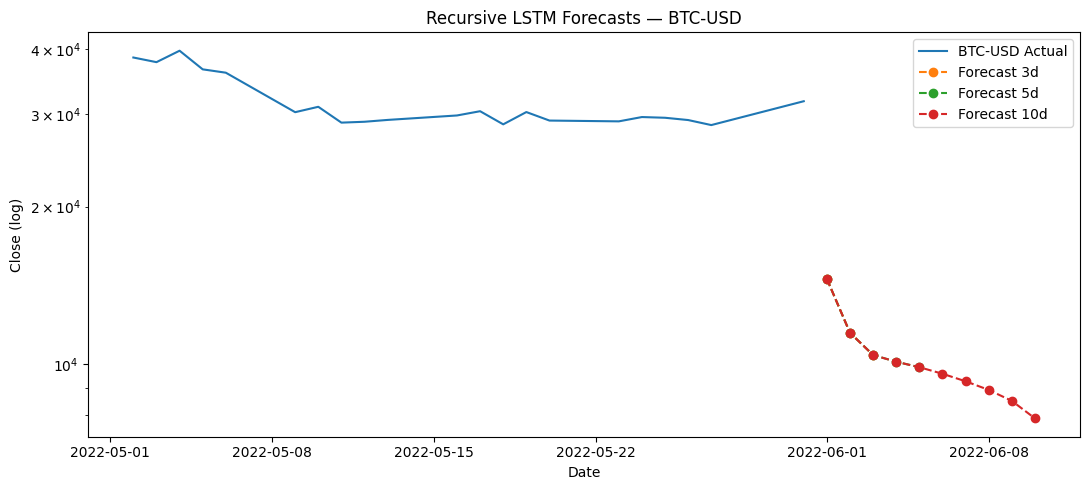

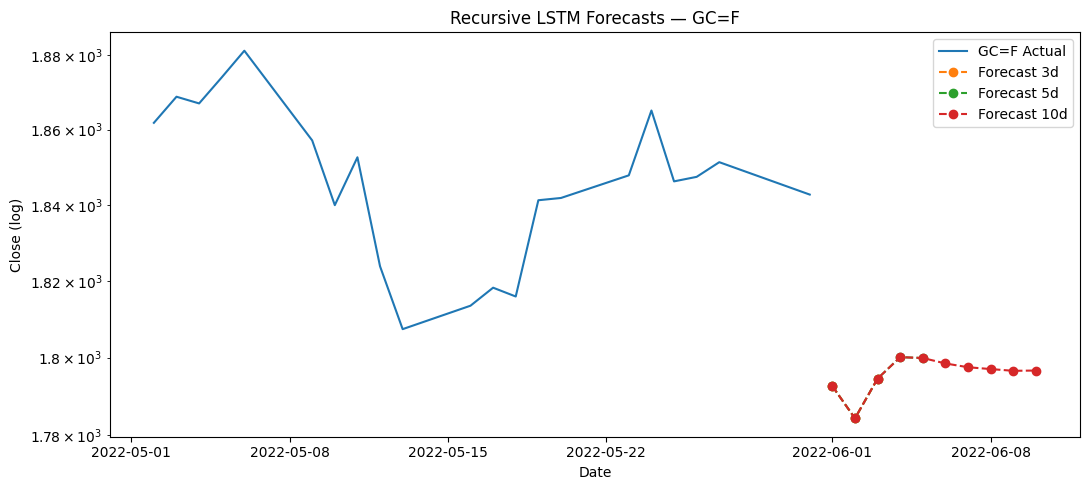

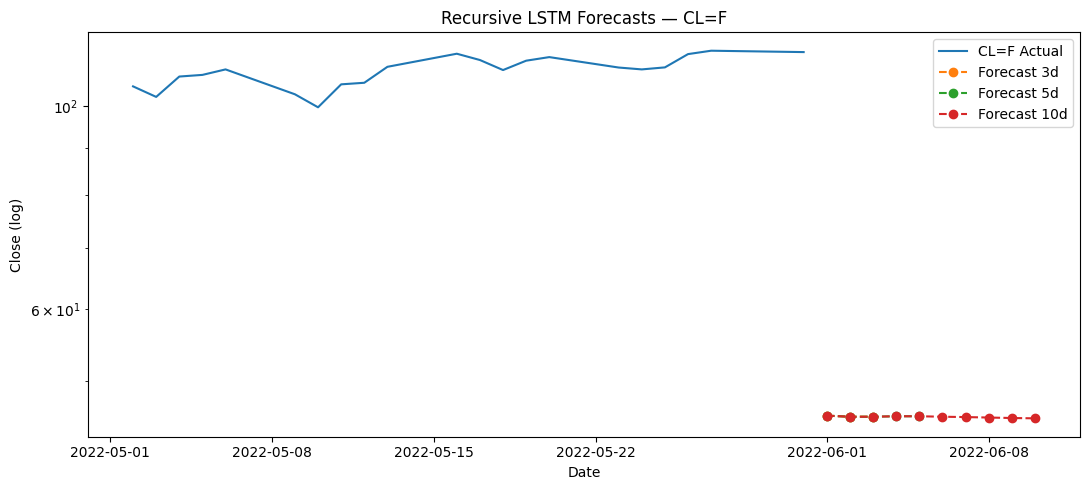

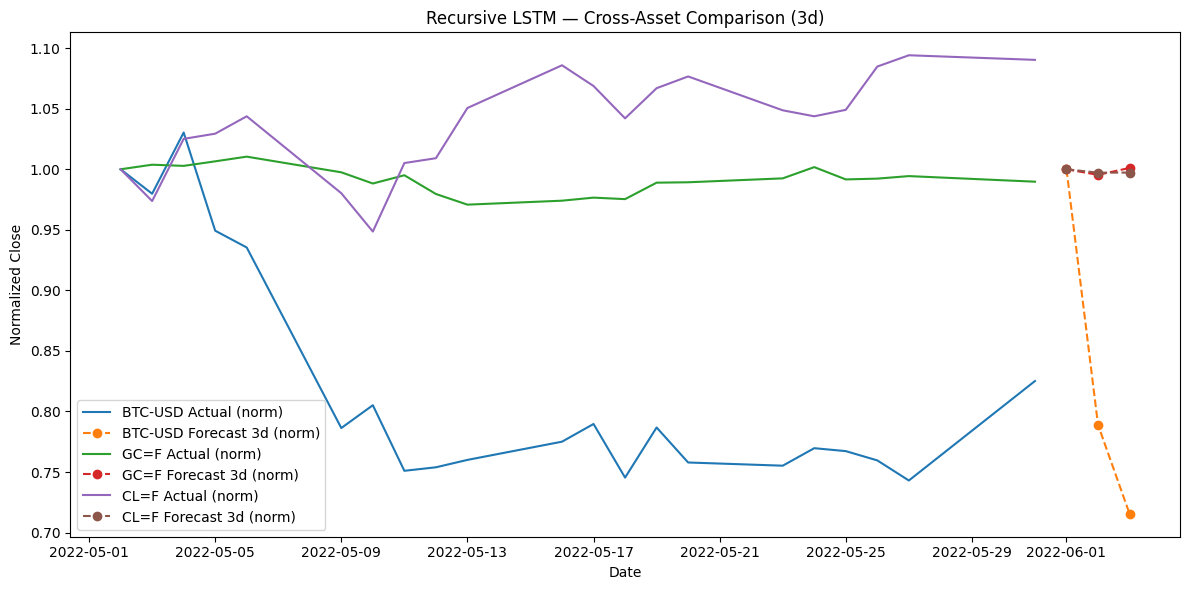

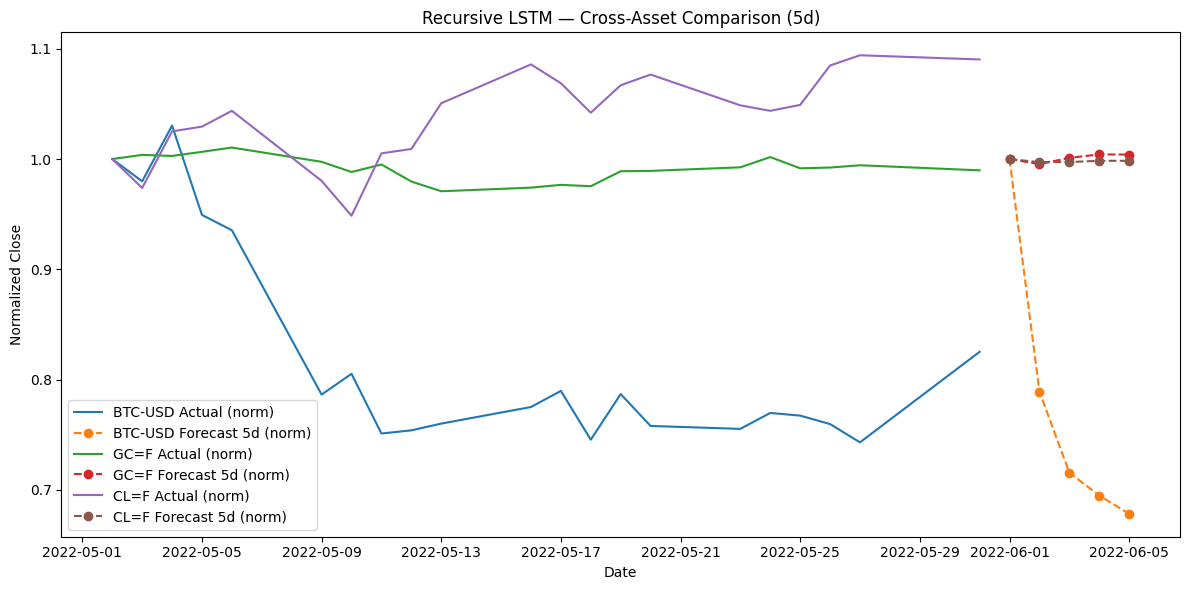

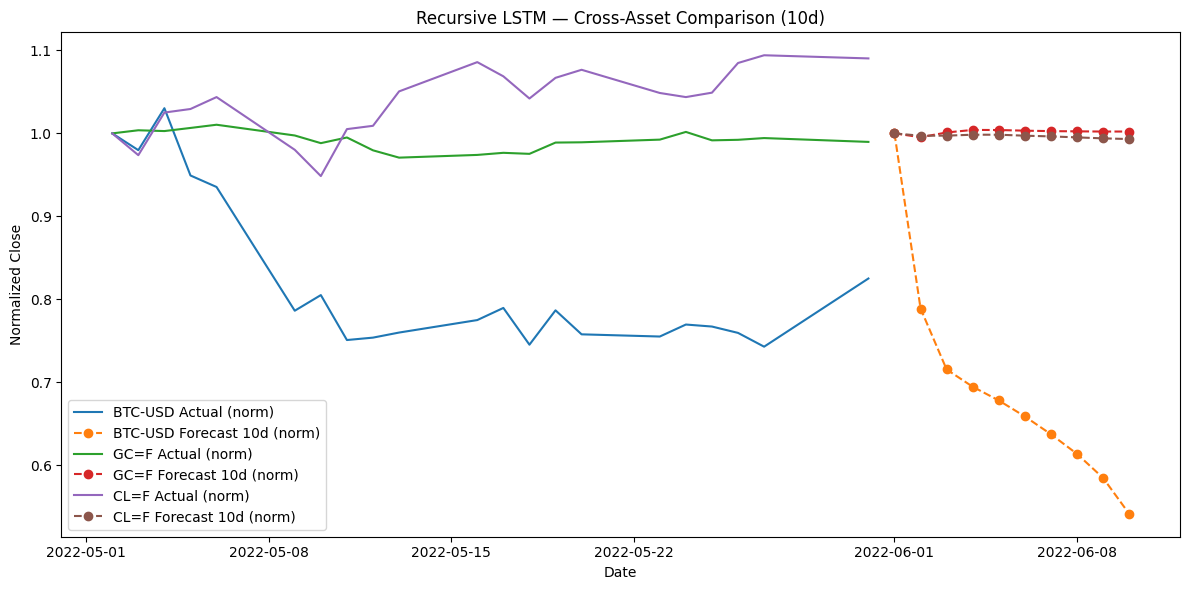

In [138]:
# 1) آموزش برای هر دارایی و ساخت پیش‌بینی‌های 3/5/10 روزه
models, metas, forecasts = train_and_recursive_forecast_all(
    df_all=df_all,
    train_df=train_cal,   
    val_df=val_cal,
    horizons=HORIZONS
)

# 2) نمودار هر دارایی در یک نمودار 
for t in TICKERS:
    plot_asset_with_horizons(df_all, forecasts[t], t, lookback_days=120, save=None)

# 3) نمودار مقایسه‌ای بین دارایی‌ها
for h in HORIZONS:
    plot_compare_assets(df_all, forecasts, horizon=h, lookback_days=120, normalize=True, save=None)